A Simple Guide to Tabular Regression Using FastAI

This tutorial demonstrates how to train a basic regression model using tabular data with FastAI.

The supplied example dataset is procedurally generated and contains numerical and categorical variables describing simple geometric shapes. The workflow is intentionally simple so that the example columns and target variable can be replaced with data from another application.


The first step is to import the Python packages required for the tutorial.

Pandas is used to organise and work with tabular data, os is used for file and directory operations, and FastAI provides the tabular machine-learning tools used below.


In [1]:
import pandas as pd
import os
from fastai.tabular.all import *

The following block checks whether the example dataset is already available.

If the required data cannot be found, the notebook runs the supplied data-generation notebook to create it.

If you are using your own dataset, this step can be omitted or modified as required.


In [2]:
Image_path = '../images_assorted'

if os.path.exists(Image_path):
    print("The file exists.")
else:
    %run ../GenerateVolumes.ipynb

The file exists.


The next step is to load the dataframe containing the variables for each sample. In this regression example, the model will be trained to predict the Radius column from the remaining selected tabular inputs.


In [3]:
df_path = '../image_data_assorted.csv'
df = pd.read_csv(df_path)

The supplied example dataset contains 1,000 procedurally generated samples based on circles, triangles, and squares.

For each sample, the dataset contains variables describing the generated shape, including its position, area, perimeter-like measurement, volume, radius, and categorical shape label. These variables provide a simple dataset for demonstrating how continuous and categorical inputs are handled in a tabular model.


In [4]:
df.head()

,Radius,X_Position,Y_Position,Area,Surface2d,Volume,image_path,mask_path,shape
0,53,254,209,1404,181,148877,images_assorted/image_1.png,masks_assorted/mask_1.png,triange
1,19,158,255,1134,60,28716,images_assorted/image_2.png,masks_assorted/mask_2.png,circle
2,84,421,391,7056,336,592704,images_assorted/image_3.png,masks_assorted/mask_3.png,square
3,75,101,86,17662,236,1766250,images_assorted/image_4.png,masks_assorted/mask_4.png,circle
4,113,429,331,6384,386,1442897,images_assorted/image_5.png,masks_assorted/mask_5.png,triange


Before creating the dataloader, the input columns must be separated into continuous and categorical variables.

Continuous variables contain numerical values that can be supplied to the model as numerical features. Categorical variables represent discrete groups or labels that FastAI can encode appropriately.

One way to define the continuous inputs is to begin with all dataframe columns and remove the columns that should not be used as model inputs. In this example, image paths, mask paths, and the target variable are removed.


In [5]:
columns = df.columns

cont_names = [col for col in columns if col != 'image_path'] # removes image_path column data
cont_names = [col for col in cont_names if col != 'mask_path'] # removes mask_path column data
cont_names = [col for col in cont_names if col != 'Radius'] # removes Radius column data

Alternatively, the required input columns can be declared directly. This approach is often clearer when the number of variables is small or when only a specific subset of the available columns should be used.


In [6]:
cont_names = ['X_Position', 'Y_Position', 'Area', 'Surface2d', 'Volume']

cat_names = 'shape' # insert column names to use as inputs with Numerical values here
target = 'Radius'

In [7]:
# use this to check if columns are in the right list
print(cat_names)
print(cont_names)
print(df.dtypes)


shape
['X_Position', 'Y_Position', 'Area', 'Surface2d', 'Volume']
Radius         int64
X_Position     int64
Y_Position     int64
Area           int64
Surface2d      int64
Volume         int64
image_path    object
mask_path     object
shape         object
dtype: object


FastAI provides dedicated tabular dataloader tools that handle much of the preprocessing required for standard tabular models.

The main inputs used here are:

- df_path: the path to the CSV file containing the dataset.
- y_names: the column containing the target value.
- cat_names: the categorical input columns.
- cont_names: the continuous numerical input columns.
- bs: the batch size used during training.
- procs: preprocessing operations applied to the tabular data.

The supplied preprocessing steps categorise categorical variables, fill missing values where required, and normalise continuous variables before training.


In [8]:
batch_size = 64      # where you declare batch size

dls = TabularDataLoaders.from_csv( 
df_path,                    # Path to the CSV file 
y_names=target,             # Name of the target column 
cat_names=cat_names,        # List of categorical data column names 
cont_names=cont_names,      # List of continuous values column names 
bs=batch_size ,           # Batch size
procs=[Categorify, FillMissing, Normalize] ,
batch_tfms=[IntToFloatTensor()]
)

Before training, it is useful to inspect a batch produced by the dataloader to confirm that the intended input columns and target values are being loaded correctly.

For tabular data, show_batch() displays the processed samples as a table. The target column is included alongside the selected input variables, making this a useful check before model training begins.


In [9]:
dls.show_batch()

,shape,X_Position,Y_Position,Area,Surface2d,Volume,Radius
0,circle,240.000000,375.999995,7539.000013,153.999997,4.925570e+05,49.0
1,square,171.999998,372.999994,8281.000006,364.000001,7.535710e+05,91.0
2,square,178.000000,247.000000,9409.000045,388.000004,9.126730e+05,97.0
3,triange,337.999999,249.000000,5939.999997,371.999998,1.295029e+06,109.0
4,square,141.999999,198.999998,10816.000114,415.999999,1.124864e+06,104.0
5,triange,180.999998,236.999999,1681.999785,198.000001,1.951120e+05,58.0
6,square,206.000002,414.000003,484.000126,87.999996,1.064800e+04,22.0
7,square,259.000000,435.000005,7568.999991,347.999995,6.585030e+05,87.0
8,square,160.000000,345.000003,360.999919,75.999995,6.859033e+03,19.0
9,square,118.999998,160.000001,9801.000045,396.000001,9.702990e+05,99.0


The next step is to create the FastAI tabular learner.

The tabular_learner function automatically constructs a feed-forward neural network that is suitable for many standard tabular problems. The default architecture can be used directly, or the hidden-layer sizes can be changed using the layers argument.

For example, layers=[200, 200, 200] would create three hidden fully connected layers containing 200 units each.

For applications that require substantially different model architectures or custom handling of the model inputs, a standard FastAI Learner can instead be created around a custom PyTorch model. That more manual approach is demonstrated in the accompanying custom tabular classification tutorial.


In [10]:

learn = tabular_learner(dls, metrics=rmse)

In [ ]:
Before training, FastAIs learning-rate finder can be used to identify a suitable learning rate.

The resulting plot shows how the loss changes as the learning rate is increased. A useful value is generally selected from the region where the loss is decreasing consistently, before the learning rate becomes large enough to destabilise training.

In this tutorial, FastAI returns both minimum-loss and steepest-slope suggestions, and the steepest-slope value is subsequently used for training.


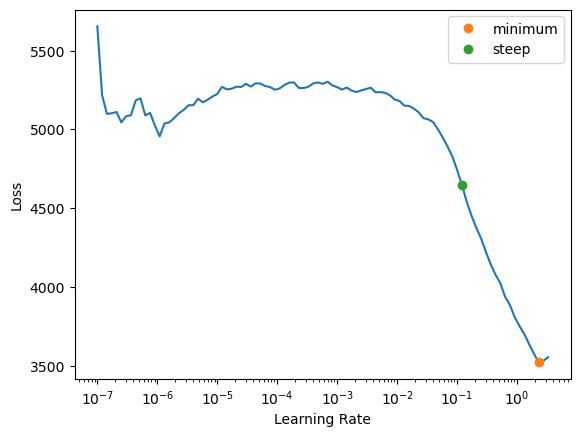

In [11]:
lr_min,lr_steep = learn.lr_find(suggest_funcs=(minimum, steep))

The model can now be trained.

For this tabular learner, the fit_one_cycle method is used. The first argument specifies the number of training epochs, while lr_max specifies the learning rate selected in the previous step.

Further discussion of training methods, epoch selection, and interpretation of training outputs is provided in the Chapter 2 appendix.


In [12]:

learn.fit_one_cycle(50,lr_max=lr_steep)

epoch,train_loss,valid_loss,_rmse,time
0,5273.362793,4738.459473,68.836472,00:00
1,4791.541016,3849.964600,62.048084,00:00
2,4346.150879,3231.124023,56.842979,00:00
3,3620.120605,1004.933838,31.700693,00:00
4,2589.731201,444.960388,21.094084,00:00
5,1933.922729,64.472160,8.029454,00:00
6,1446.979614,46.965816,6.853160,00:00
7,1089.490356,102.213165,10.110053,00:00
8,835.014587,10.947845,3.308753,00:00
9,649.518372,102.470062,10.122749,00:00


After training, the model should be evaluated to determine whether training behaved appropriately and whether its predictions are sufficiently accurate for the intended application.

There are many approaches to regression-model evaluation. This tutorial demonstrates two useful introductory methods: examining the training and validation losses and comparing predicted values with their corresponding target values.


The first evaluation step is to plot the training and validation losses across the training epochs.

These curves provide information about how the model learned during training and can help identify problems such as overfitting, underfitting, or training that stopped before convergence. Loss curves do not directly establish whether the model is sufficiently accurate for its intended use, but they are useful for diagnosing the training process.


<bound method Recorder.plot_loss of Recorder>


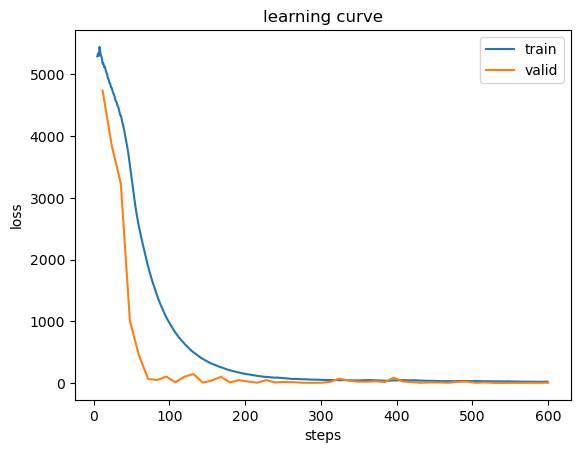

In [13]:
# Plot the losses
learn.recorder.plot_loss()
print(learn.recorder.plot_loss)
# Set the y-axis limits (replace with your desired limits)
#plt.ylim(0, 5)  # sets y-axis limits 
# Show the plot with updated y-limits
plt.show()

In a successful training run, the training and validation losses should generally decrease and then stabilise. A sustained increase in validation loss while training loss continues to decrease can indicate overfitting, while both losses continuing to decrease at the end of training can indicate that additional training may still improve the model.

These patterns should be interpreted alongside task-specific performance metrics rather than using a fixed numerical difference between the training and validation losses.


Regression performance can also be evaluated by directly comparing model predictions with the corresponding ground-truth target values.

A simple way to visualise this relationship is to plot the predicted value against the actual target value for every sample in the validation dataset. The following code generates this comparison.


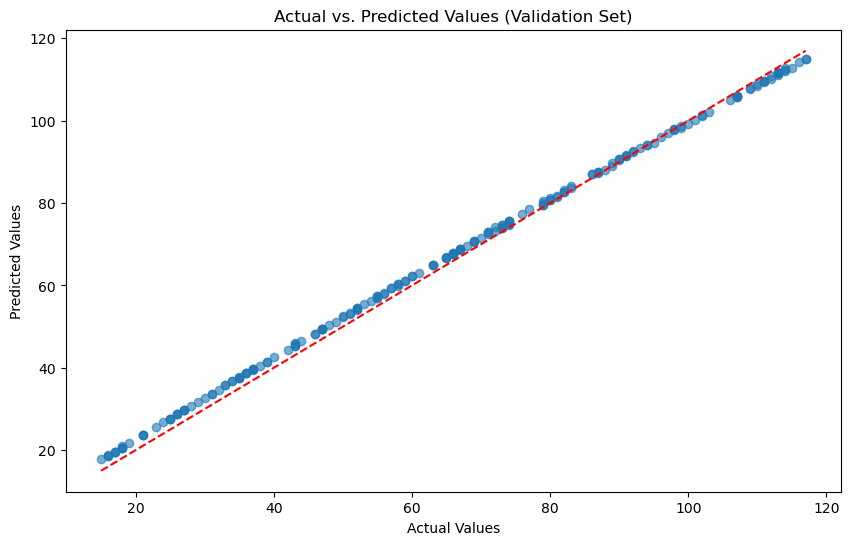

In [14]:

# extract predictions vs target value for the validatin dataset
preds, targets = learn.get_preds(ds_idx=1)  # ds_idx=1 for the validation set


import matplotlib.pyplot as plt

# Convert tensors to numpy arrays if necessary
actual_values = targets.numpy()
predicted_values = preds.numpy()

# Plotting
plt.figure(figsize=(10, 6))
plt.scatter(actual_values, predicted_values, alpha=0.6)
plt.plot([actual_values.min(), actual_values.max()], [actual_values.min(), actual_values.max()], color='red', linestyle='--')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs. Predicted Values (Validation Set)')
plt.show()

For an accurate regression model, the predicted values should cluster around the line representing agreement between prediction and target.

The distribution of points around this line can also help identify ranges of the target variable where the model performs less reliably or shows systematic bias.


Exporting and using the trained model


Saving the trained model

The trained learner can be exported to a .pkl file using learn.export(). This allows the model to be loaded later without repeating the training process.


In [15]:
learn.export('exported_classification_tabular_model.pkl')

Loading an exported model

An exported FastAI learner can be loaded using load_learner() by providing the path to the saved .pkl file. The loaded learner can then be used directly for inference on new tabular samples.


In [16]:
learn2 = load_learner('exported_classification_tabular_model.pkl')   # using learner2 to show its loading

C:\Users\bowan\anaconda3\Lib\site-packages\fastai\learner.py:455: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  warn("load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.\nIf you only need to load model weights and optimizer state, use the safe `Learner.load` instead.")


The following example selects one row from the dataframe, extracts the same input columns used during training, and passes the resulting sample to the loaded model.

FastAI's predict method then returns the prediction together with the processed input representation.


In [17]:

# Get the nth row (e.g., 2nd row)
n = 1  # Remember, indexing starts at 0
orginalrow = df.iloc[n]
print(f'GroundTurth value {orginalrow["Radius"]}')
                 
df_selected = df[cont_names+[cat_names]] # if just a string 
#df_selected = df[cont_names+[cat_names]] # if cat_names is a list
nth_row = df_selected.iloc[n]

DataSeries_with_appended_prediction, PredictionValue1, PredictionValue2 =learn2.predict(nth_row)

print(DataSeries_with_appended_prediction)
print(PredictionValue1)
print(PredictionValue2)

GroundTurth value 19


   shape  X_Position  Y_Position      Area  Surface2d    Volume     Radius
0    1.0   -0.866363   -0.009026 -0.716171  -1.610522 -0.670515  21.827229
tensor([21.8272])
tensor([21.8272])


For this regression model, predict returns three related outputs:

- DataSeries_with_appended_prediction: the processed input row with the model prediction appended.
- PredictionValue1: the decoded numerical prediction.
- PredictionValue2: the corresponding raw numerical model output.

For a simple single-output regression model, these outputs represent the same underlying prediction in different forms.


This completes the basic tabular-regression workflow. The tutorial has demonstrated how to select continuous and categorical input variables, construct FastAI tabular dataloaders, train and evaluate a regression model, export the trained learner, and generate predictions for new tabular samples. The same workflow can be adapted to other tabular-regression problems by changing the input columns, target variable, model settings, and training configuration.
